# UCS420 Assignment 10
### Heart Health Information Assistant

Gurkirpa Singh, 3Q34, 1024170378

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Blakkbird/Gurkirpa_Singh_Sarao_1024170378_UCS420/blob/main/Cognitive_as10.ipynb)

My roll number is even, so this is the **Heart Health Information Assistant**.

It takes a question about heart health, works out what the user is asking about (the intent), checks a few safety rules,
and answers from a small knowledge base. The steps follow the lab: labelled corpus, taxonomy, ontology,
NLP preprocessing, learning, reasoning and knowledge retrieval, then the integrated assistant and deployment.

In [1]:
import re
import nltk
import numpy as np
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

ModuleNotFoundError: No module named 'nltk'

## 1. Labelled Corpus

105 queries across 7 intents (15 each). The intents are: `symptoms`, `risk_factors`, `diet`, `exercise`, `tests`, `medication` and `monitoring`.

In [ ]:
corpus = {
    "symptoms": [
        "What are the symptoms of heart disease?",
        "How do I know if I have a heart problem?",
        "What does angina feel like?",
        "Is chest discomfort a sign of heart trouble?",
        "Can heart disease cause tiredness and swelling in the legs?",
        "What are the early warning signs of a weak heart?",
        "Do women get different heart symptoms than men?",
        "Why do I feel palpitations sometimes?",
        "Is breathlessness while climbing stairs related to the heart?",
        "What signs show that my heart is not pumping properly?",
        "What are the signs of a heart attack in women?",
        "Can heart problems cause dizziness?",
        "Is pain in the left arm a heart symptom?",
        "Does heart failure cause swollen ankles?",
        "What symptoms does a blocked artery cause?",
    ],
    "risk_factors": [
        "What increases the risk of heart disease?",
        "Does smoking affect my heart?",
        "Can high cholesterol lead to heart problems?",
        "Is heart disease hereditary?",
        "Does diabetes raise the chance of heart disease?",
        "How does stress affect the heart?",
        "Am I at risk if I am overweight?",
        "Does drinking alcohol harm the heart?",
        "Which habits put my heart in danger?",
        "At what age does heart disease risk go up?",
        "Does obesity increase heart disease risk?",
        "Is a sedentary lifestyle a risk factor for the heart?",
        "Does high blood pressure damage the heart over time?",
        "Are young people at risk of heart disease?",
        "Does family history increase my risk of heart problems?",
    ],
    "diet": [
        "What foods are good for the heart?",
        "Which foods should I avoid for a healthy heart?",
        "How much salt should I eat per day?",
        "Is ghee bad for my heart?",
        "Are eggs safe for heart patients?",
        "What is a heart healthy diet plan?",
        "Should I cut down on fried food?",
        "Are nuts good for heart health?",
        "Does eating fish help the heart?",
        "What should I eat to lower my cholesterol?",
        "Is red meat bad for the heart?",
        "Which cooking oil is best for heart health?",
        "Is coffee bad for my heart?",
        "Should heart patients avoid sugar?",
        "What fruits and vegetables protect the heart?",
    ],
    "exercise": [
        "How much exercise is good for the heart?",
        "Is walking good for heart health?",
        "Can heart patients go to the gym?",
        "What kind of workout strengthens the heart?",
        "How many minutes should I exercise every week?",
        "Is yoga helpful for the heart?",
        "Is it safe to run if I have a heart condition?",
        "Does sitting all day affect my heart?",
        "What exercise is safe during cardiac recovery?",
        "Can cycling improve my heart fitness?",
        "Is swimming a good exercise for the heart?",
        "How do I start exercising safely for my heart?",
        "Does regular physical activity make the heart stronger?",
        "Can I lift weights with a heart problem?",
        "How long should I walk daily for a healthy heart?",
    ],
    "tests": [
        "How is heart disease diagnosed?",
        "What is an ECG test?",
        "Why would a doctor order an echocardiogram?",
        "What does a stress test check?",
        "What is a lipid profile?",
        "When do I need an angiography?",
        "Which tests check the health of my heart?",
        "What does a TMT test involve?",
        "How often should I get a heart checkup?",
        "What does troponin in a blood test mean?",
        "What does an echo test show?",
        "Is a treadmill test safe?",
        "What blood tests are done for the heart?",
        "What is a coronary angiogram?",
        "What does an abnormal ECG mean?",
    ],
    "medication": [
        "What medicines are used for heart disease?",
        "What are statins used for?",
        "Should I take aspirin daily for my heart?",
        "Can I stop my blood pressure tablets if I feel fine?",
        "What are the side effects of heart medicines?",
        "What do beta blockers do?",
        "Can I take painkillers with my heart medication?",
        "What happens if I miss a dose of my heart tablet?",
        "Do blood thinners have any risks?",
        "How long do I need to take cholesterol medicine?",
        "Can I take heart medicine with food?",
        "What is clopidogrel prescribed for?",
        "Are statins safe for long term use?",
        "Which tablets lower blood pressure?",
        "Should I take my heart pills at night or in the morning?",
    ],
    "monitoring": [
        "What is a normal blood pressure reading?",
        "How do I check my blood pressure at home?",
        "What is a healthy cholesterol level?",
        "Is 140/90 high blood pressure?",
        "What is a normal resting heart rate?",
        "How often should I measure my blood pressure?",
        "What should my LDL level be?",
        "Which BP monitor should I buy?",
        "Is a heart rate of 110 normal while resting?",
        "How can I track my heart numbers regularly?",
        "What is a good blood pressure for my age?",
        "How often should I recheck my cholesterol numbers?",
        "Is a smartwatch heart rate reading accurate?",
        "What is the ideal heart rate during rest?",
        "What does high systolic pressure mean?",
    ],
}

queries, labels = [], []
for intent, qs in corpus.items():
    queries += qs
    labels += [intent] * len(qs)

print("total queries:", len(queries))
for intent, qs in corpus.items():
    print(f"  {intent:13s} {len(qs)}")

total queries: 105
  symptoms      15
  risk_factors  15
  diet          15
  exercise      15
  tests         15
  medication    15
  monitoring    15


## 2. Taxonomy

4 major categories, each with 2 subcategories. Six of the subcategories map directly to an intent.
`Emergency Signs` is not a trained intent since it is handled by a rule before the classifier, and `Monitoring` covers blood pressure, cholesterol and heart rate tracking.

In [ ]:
taxonomy = {
    "Understanding Heart Disease": {
        "Symptoms": "symptoms",
        "Risk Factors": "risk_factors",
    },
    "Prevention and Lifestyle": {
        "Diet": "diet",
        "Exercise": "exercise",
    },
    "Diagnosis and Treatment": {
        "Tests": "tests",
        "Medication": "medication",
    },
    "Monitoring and Safety": {
        "Monitoring": "monitoring",
        "Emergency Signs": "emergency (rule)",
    },
}

for cat, subs in taxonomy.items():
    print(cat)
    for sub, intent in subs.items():
        print(f"   |-- {sub}  ->  {intent}")

Understanding Heart Disease
   |-- Symptoms  ->  symptoms
   |-- Risk Factors  ->  risk_factors
Prevention and Lifestyle
   |-- Diet  ->  diet
   |-- Exercise  ->  exercise
Diagnosis and Treatment
   |-- Tests  ->  tests
   |-- Medication  ->  medication
Monitoring and Safety
   |-- Monitoring  ->  monitoring
   |-- Emergency Signs  ->  emergency (rule)


## 3. Ontology

Domain concepts and the relationships between them, stored as a nested dictionary like in the lab.
The assistant uses this later: if a query mentions a concept, it adds a related fact to the answer.

In [ ]:
ontology = {
    "Heart Disease": {
        "has_symptom": ["Chest Pain", "Shortness of Breath"],
        "diagnosed_by": ["ECG", "Echocardiogram"],
        "managed_by": ["Statins", "Healthy Diet", "Exercise"],
    },
    "Smoking": {"increases_risk_of": ["Heart Disease"]},
    "Diabetes": {"increases_risk_of": ["Heart Disease"]},
    "High Blood Pressure": {
        "increases_risk_of": ["Heart Disease"],
        "measured_by": ["BP Monitor"],
        "reduced_by": ["Exercise", "Low Salt Diet"],
    },
    "High Cholesterol": {
        "increases_risk_of": ["Heart Disease"],
        "measured_by": ["Lipid Profile"],
        "treated_by": ["Statins"],
        "reduced_by": ["Healthy Diet"],
    },
    "Chest Pain": {"may_indicate": ["Heart Attack"]},
    "Heart Attack": {
        "detected_by": ["ECG", "Troponin Test"],
        "requires": ["Emergency Care"],
    },
}

# flatten into (subject, relation, object) triples
triples = []
for subj, rels in ontology.items():
    for rel, objs in rels.items():
        for obj in objs:
            triples.append((subj, rel, obj))

concepts = sorted({t[0] for t in triples} | {t[2] for t in triples})
print("concepts:", len(concepts))
print(", ".join(concepts))
print("\nrelationships:", len(triples))
for s, r, o in triples:
    print(f"  {s} --{r}--> {o}")

concepts: 18
BP Monitor, Chest Pain, Diabetes, ECG, Echocardiogram, Emergency Care, Exercise, Healthy Diet, Heart Attack, Heart Disease, High Blood Pressure, High Cholesterol, Lipid Profile, Low Salt Diet, Shortness of Breath, Smoking, Statins, Troponin Test

relationships: 21
  Heart Disease --has_symptom--> Chest Pain
  Heart Disease --has_symptom--> Shortness of Breath
  Heart Disease --diagnosed_by--> ECG
  Heart Disease --diagnosed_by--> Echocardiogram
  Heart Disease --managed_by--> Statins
  Heart Disease --managed_by--> Healthy Diet
  Heart Disease --managed_by--> Exercise
  Smoking --increases_risk_of--> Heart Disease
  Diabetes --increases_risk_of--> Heart Disease
  High Blood Pressure --increases_risk_of--> Heart Disease
  High Blood Pressure --measured_by--> BP Monitor
  High Blood Pressure --reduced_by--> Exercise
  High Blood Pressure --reduced_by--> Low Salt Diet
  High Cholesterol --increases_risk_of--> Heart Disease
  High Cholesterol --measured_by--> Lipid Profile
  H

## 4. NLP Processing

Lowercase, tokenize, remove stopwords and punctuation, then lemmatize. For example *"medicines"* becomes *"medicine"* and *"tablets"* becomes *"tablet"*.

In [ ]:
stop = set(stopwords.words("english"))
lem = WordNetLemmatizer()

def preprocess(text):
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if re.search(r"[a-z0-9]", t)]   # drop punctuation
    tokens = [t for t in tokens if t not in stop]
    tokens = [lem.lemmatize(t) for t in tokens]
    return " ".join(tokens)

for q in ["What medicines are used for heart disease?", "Can I stop my blood pressure tablets if I feel fine?"]:
    print(q, "->", preprocess(q))

clean = [preprocess(q) for q in queries]

What medicines are used for heart disease? -> medicine used heart disease
Can I stop my blood pressure tablets if I feel fine? -> stop blood pressure tablet feel fine


## 5. Learning

TF-IDF (unigrams and bigrams) for features, and Logistic Regression as the classifier. Logistic Regression gives class probabilities,
which the assistant needs for the low-confidence rule. 25% of the corpus is held out for testing, split so every intent appears in both sets.

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    clean, labels, test_size=0.25, stratify=labels, random_state=42)

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
xtr = vec.fit_transform(x_train)
xte = vec.transform(x_test)

model = LogisticRegression(C=10, max_iter=1000)
model.fit(xtr, y_train)
pred = model.predict(xte)

print("train size:", len(x_train), " test size:", len(x_test))
print("vocabulary size:", len(vec.vocabulary_))

train size: 78  test size: 27
vocabulary size: 384


### Evaluation

In [ ]:
print(f"accuracy: {accuracy_score(y_test, pred):.2f}\n")
print(classification_report(y_test, pred, zero_division=0))

# 5-fold cross validation gives a steadier estimate than one small split
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
cv = cross_val_score(make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),
                                   LogisticRegression(C=10, max_iter=1000)), clean, labels, cv=5)
print("5-fold cv accuracy:", cv.round(2), " mean:", round(cv.mean(), 2))

accuracy: 0.63

              precision    recall  f1-score   support

        diet       0.50      0.67      0.57         3
    exercise       0.25      0.50      0.33         4
  medication       1.00      0.50      0.67         4
  monitoring       0.67      1.00      0.80         4
risk_factors       1.00      0.75      0.86         4
    symptoms       1.00      0.50      0.67         4
       tests       1.00      0.50      0.67         4

    accuracy                           0.63        27
   macro avg       0.77      0.63      0.65        27
weighted avg       0.78      0.63      0.65        27

5-fold cv accuracy: [0.57 0.71 0.52 0.71 0.71]  mean: 0.65


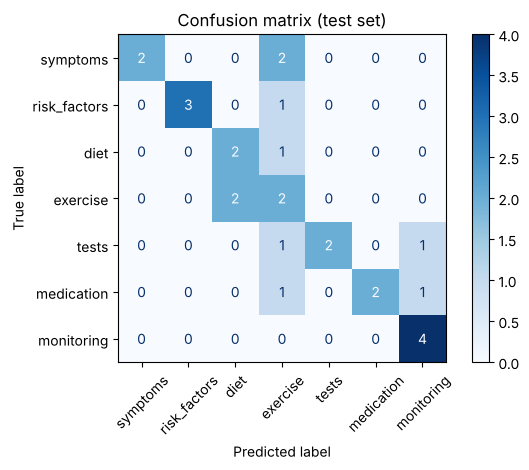

In [ ]:
names = list(corpus.keys())
cm = confusion_matrix(y_test, pred, labels=names)
ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.show()

With only 15 queries per intent, the test set has only 3 or 4 queries per class, so one mistake shifts the scores a lot,
which is why the 5-fold cross validation mean is the more reliable number. Most errors are between intents that share words,
like exercise, diet and risk factors (all of them talk about a "healthy heart").
For the assistant itself the model is retrained on all 105 queries, since more examples help more than holding data back.

In [ ]:
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
x_all = vec.fit_transform(clean)
model = LogisticRegression(C=10, max_iter=1000)
model.fit(x_all, labels)
print("final model trained on", len(clean), "queries")

final model trained on 105 queries


## 6. Knowledge Base

General information for each intent, written from standard public health guidance (WHO, American Heart Association).
It is meant as information, not medical advice.

In [ ]:
knowledge = {
    "symptoms": (
        "Common signs of heart disease are chest pain or pressure (angina), shortness of breath, "
        "pain that spreads to the arm, jaw, neck or back, unusual tiredness, palpitations, dizziness, "
        "and swelling in the legs or ankles. Women, older adults and people with diabetes may have milder "
        "or less typical symptoms like nausea or fatigue."
    ),
    "risk_factors": (
        "The main risk factors are high blood pressure, high LDL cholesterol, smoking, diabetes, obesity, "
        "physical inactivity, an unhealthy diet, too much alcohol, long-term stress, a family history of "
        "heart disease, and increasing age. Most of these can be reduced with lifestyle changes and treatment."
    ),
    "diet": (
        "A heart-healthy diet is built on vegetables, fruits, whole grains, pulses, nuts and fish. "
        "Keep salt under 5 g a day (about one teaspoon), and limit fried food, sugary drinks, processed meat, "
        "and saturated or trans fats such as vanaspati. Ghee and butter are fine in small amounts."
    ),
    "exercise": (
        "Aim for at least 150 minutes of moderate activity a week, such as brisk walking, cycling or swimming, "
        "for example 30 minutes on 5 days. Yoga and light strength training help too. Reduce long periods of sitting. "
        "If you already have a heart condition, ask your doctor what level of exercise is safe for you."
    ),
    "tests": (
        "Common heart tests are an ECG (electrical activity), an echocardiogram (ultrasound of the heart), "
        "a stress test or TMT (heart under exercise), a lipid profile (cholesterol), blood sugar tests, and "
        "troponin (a blood marker for heart muscle damage). Angiography is used to look for blocked arteries."
    ),
    "medication": (
        "Heart medicines include statins (lower cholesterol), blood thinners like aspirin or clopidogrel, "
        "beta blockers, ACE inhibitors and other blood pressure medicines. Take them exactly as prescribed. "
        "Do not start aspirin on your own or stop any heart medicine without talking to your doctor."
    ),
    "monitoring": (
        "A normal blood pressure is below 120/80 mmHg, and readings that stay at 130/80 or above count as high "
        "and should be discussed with a doctor. A normal resting heart rate is 60 to 100 beats per minute. "
        "For cholesterol, an LDL under 100 mg/dL is generally desirable. Check BP at home after 5 minutes of rest, "
        "seated, with a validated automatic monitor."
    ),
}

## 7. Reasoning Rules

The rules run around the classifier, roughly in this order:

1. **Emergency escalation**: phrases that describe an emergency happening now (severe chest pain, can't breathe, fainted, pain spreading to the arm) skip everything else and tell the user to call 112 / 108.
2. **Greeting**: hi or hello gets a short intro instead of a classification.
3. **Unsupported query**: health topics outside heart health (skin, teeth, eyes, pregnancy and so on), or queries with no words the model knows, get a polite "outside my scope" reply.
4. **Low confidence**: if the top class probability is below the threshold, the assistant asks the user to rephrase and shows its best guesses.
5. **Medication safety**: if a query talks about stopping, skipping or changing a medicine, the answer is switched to the medication intent (even if the classifier picked something else) and gets an extra warning to check with the doctor first.
6. **Ontology facts**: if the query mentions a known concept (smoking, cholesterol, blood pressure...), a related fact from the ontology is added.
7. **Disclaimer**: every health answer ends with a reminder that this is general information, not a diagnosis.

In [ ]:
emergency_patterns = [
    r"severe chest pain", r"crushing", r"chest pain (right )?now",
    r"can'?t breathe", r"cannot breathe", r"not breathing", r"unable to breathe",
    r"faint(ed|ing)", r"collaps(e|ed|ing)", r"unconscious",
    r"(having|had) a heart attack", r"(pain|ache) spreading to (my )?(left )?(arm|jaw)",
    r"sweating .*chest pain", r"chest pain .*sweating", r"call (an )?ambulance",
]

unsupported_patterns = [
    r"\btooth", r"\bteeth\b", r"\bdental\b", r"\bskin\b", r"\brash", r"\bacne\b", r"\beyes?\b",
    r"\bvision\b", r"\bhair\b", r"\bdandruff\b", r"\bpregnan", r"\bperiods?\b", r"\bkidney",
    r"\bliver\b", r"\bfracture", r"\bbones?\b", r"\bcovid", r"\bmigraine", r"\ballerg", r"\bears?\b",
]

med_words = r"\b(medicine|medication|tablet|pill|dose|statin|aspirin|blood thinner)"
risky_verbs = r"\b(stop|skip|miss|double|change|reduce|quit)"

greetings = {"hi", "hello", "hey", "namaste", "good morning", "good evening"}

concept_words = {
    "Smoking": ["smok", "cigarette", "tobacco"],
    "Diabetes": ["diabet", "blood sugar"],
    "High Blood Pressure": ["blood pressure", " bp", "hypertension", "140/90"],
    "High Cholesterol": ["cholesterol", "ldl", "lipid"],
    "Chest Pain": ["chest pain", "chest discomfort", "angina"],
    "Exercise": ["exercise", "walk", "workout", "gym", "yoga", "cycling", "run"],
    "Statins": ["statin"],
    "ECG": ["ecg", "ekg"],
}

THRESHOLD = 0.35
EMERGENCY_MSG = ("This sounds like it could be a medical emergency. Call 112 or 108 for an ambulance right now, "
                 "or get someone to take you to the nearest hospital emergency department. Do not drive yourself, "
                 "and sit down and rest while you wait.")
DISCLAIMER = "(General information only, not a diagnosis. Please consult a doctor for personal advice.)"

def is_emergency(q):
    return any(re.search(p, q) for p in emergency_patterns)

def is_unsupported(q):
    return any(re.search(p, q) for p in unsupported_patterns)

def ontology_fact(q):
    q = " " + q
    for concept, keys in concept_words.items():
        if any(k in q for k in keys):
            for s, r, o in triples:
                if s == concept or o == concept:
                    return f"Related: {s} {r.replace('_', ' ')} {o}."
    return None

## 8. Cognitive Assistant

`assistant()` puts everything together: rules first, then preprocessing and the classifier, then the knowledge base and the extra rules on the answer.

In [ ]:
def assistant(query):
    q = query.lower().strip()

    if not q:
        return {"intent": None, "conf": None, "rule": "empty", "reply": "Please type a question."}

    # rule 1: emergency comes first
    if is_emergency(q):
        return {"intent": "emergency", "conf": None, "rule": "emergency escalation", "reply": EMERGENCY_MSG}

    # rule 2: greeting
    if q.strip("!. ") in greetings:
        return {"intent": None, "conf": None, "rule": "greeting",
                "reply": "Hello! I can answer questions about heart symptoms, risk factors, diet, exercise, tests, medicines and BP/cholesterol monitoring."}

    # rule 3: other health areas, or nothing the model recognises
    vecq = vec.transform([preprocess(q)])
    if is_unsupported(q) or vecq.nnz == 0:
        return {"intent": None, "conf": None, "rule": "unsupported",
                "reply": "Sorry, that is outside what I cover. I only answer heart health questions, so please ask a doctor or a general health service about this."}

    probs = model.predict_proba(vecq)[0]
    order = np.argsort(probs)[::-1]
    intent, conf = model.classes_[order[0]], probs[order[0]]

    # rule 4: low confidence
    if conf < THRESHOLD:
        guesses = ", ".join(f"{model.classes_[i]} ({probs[i]:.2f})" for i in order[:2])
        return {"intent": intent, "conf": conf, "rule": "low confidence",
                "reply": f"I'm not sure what you mean. My best guesses are {guesses}. Could you rephrase it, for example 'what foods are good for the heart?'"}

    rule = "answered"

    # rule 5: medication safety, overrides the classifier if needed
    if re.search(med_words, q) and re.search(risky_verbs, q):
        intent = "medication"
        rule = "answered + medication safety"

    reply = knowledge[intent]
    if rule.endswith("medication safety"):
        reply += " Important: don't stop, skip or change the dose of a heart medicine without asking your doctor first."

    # rule 6: related ontology fact
    fact = ontology_fact(q)
    if fact:
        reply += " " + fact

    # rule 7: disclaimer
    reply += " " + DISCLAIMER
    return {"intent": intent, "conf": conf, "rule": rule, "reply": reply}

def chat(query):
    res = assistant(query)
    conf = f"{res['conf']:.2f}" if res["conf"] is not None else "-"
    print("You:", query)
    print(f"[intent: {res['intent']} | confidence: {conf} | rule: {res['rule']}]")
    print("Assistant:", res["reply"])
    print()

## 9. Testing

### One query per intent
These are new queries, not copied from the corpus.

In [ ]:
tests = [
    "What warning signs suggest heart disease?",
    "Is my heart at risk because I smoke?",
    "Which oils are healthy for the heart?",
    "Is brisk walking enough exercise for my heart?",
    "What does an ECG show?",
    "What are the side effects of statins?",
    "What blood pressure is considered normal?",
]
for t in tests:
    chat(t)

You: What warning signs suggest heart disease?
[intent: symptoms | confidence: 0.64 | rule: answered]
Assistant: Common signs of heart disease are chest pain or pressure (angina), shortness of breath, pain that spreads to the arm, jaw, neck or back, unusual tiredness, palpitations, dizziness, and swelling in the legs or ankles. Women, older adults and people with diabetes may have milder or less typical symptoms like nausea or fatigue. (General information only, not a diagnosis. Please consult a doctor for personal advice.)

You: Is my heart at risk because I smoke?
[intent: risk_factors | confidence: 0.84 | rule: answered]
Assistant: The main risk factors are high blood pressure, high LDL cholesterol, smoking, diabetes, obesity, physical inactivity, an unhealthy diet, too much alcohol, long-term stress, a family history of heart disease, and increasing age. Most of these can be reduced with lifestyle changes and treatment. Related: Smoking increases risk of Heart Disease. (General inf

### Differently worded query

The first one is from the corpus, the second asks the same thing with different words.

In [ ]:
chat("What foods are good for the heart?")
chat("Which eating habits keep the heart healthy?")

You: What foods are good for the heart?
[intent: diet | confidence: 0.79 | rule: answered]
Assistant: A heart-healthy diet is built on vegetables, fruits, whole grains, pulses, nuts and fish. Keep salt under 5 g a day (about one teaspoon), and limit fried food, sugary drinks, processed meat, and saturated or trans fats such as vanaspati. Ghee and butter are fine in small amounts. (General information only, not a diagnosis. Please consult a doctor for personal advice.)

You: Which eating habits keep the heart healthy?
[intent: diet | confidence: 0.48 | rule: answered]
Assistant: A heart-healthy diet is built on vegetables, fruits, whole grains, pulses, nuts and fish. Keep salt under 5 g a day (about one teaspoon), and limit fried food, sugary drinks, processed meat, and saturated or trans fats such as vanaspati. Ghee and butter are fine in small amounts. (General information only, not a diagnosis. Please consult a doctor for personal advice.)



### Unsupported healthcare query

In [ ]:
chat("How do I get rid of a skin rash?")

You: How do I get rid of a skin rash?
[intent: None | confidence: - | rule: unsupported]
Assistant: Sorry, that is outside what I cover. I only answer heart health questions, so please ask a doctor or a general health service about this.



### Low-confidence query

In [ ]:
chat("Tell me about the heart")

You: Tell me about the heart
[intent: exercise | confidence: 0.29 | rule: low confidence]
Assistant: I'm not sure what you mean. My best guesses are exercise (0.29), risk_factors (0.23). Could you rephrase it, for example 'what foods are good for the heart?'



### Emergency query

In [ ]:
chat("I have severe chest pain spreading to my left arm and I'm sweating")

You: I have severe chest pain spreading to my left arm and I'm sweating
[intent: emergency | confidence: - | rule: emergency escalation]
Assistant: This sounds like it could be a medical emergency. Call 112 or 108 for an ambulance right now, or get someone to take you to the nearest hospital emergency department. Do not drive yourself, and sit down and rest while you wait.



### Other rules

In [ ]:
chat("hello")
chat("Can I skip my blood pressure medicine for a few days?")

You: hello
[intent: None | confidence: - | rule: greeting]
Assistant: Hello! I can answer questions about heart symptoms, risk factors, diet, exercise, tests, medicines and BP/cholesterol monitoring.

You: Can I skip my blood pressure medicine for a few days?
[intent: medication | confidence: 0.42 | rule: answered + medication safety]
Assistant: Heart medicines include statins (lower cholesterol), blood thinners like aspirin or clopidogrel, beta blockers, ACE inhibitors and other blood pressure medicines. Take them exactly as prescribed. Do not start aspirin on your own or stop any heart medicine without talking to your doctor. Important: don't stop, skip or change the dose of a heart medicine without asking your doctor first. Related: High Blood Pressure increases risk of Heart Disease. (General information only, not a diagnosis. Please consult a doctor for personal advice.)



## 10. Deployment (Google Colab)

Open the notebook in Colab with the badge at the top, run all cells, then use the box below to ask as many questions as you want.
The chat history stays in the output area. The widget only works in a live notebook, so it shows up as text on GitHub.

In [ ]:
import ipywidgets as widgets
from IPython.display import display

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

box = widgets.Text(placeholder="Ask a heart health question...", layout=widgets.Layout(width="70%"))
btn = widgets.Button(description="Ask", button_style="primary")
clear = widgets.Button(description="Clear")
out = widgets.Output()

def on_ask(b):
    q = box.value.strip()
    if not q:
        return
    with out:
        chat(q)
    box.value = ""

btn.on_click(on_ask)
clear.on_click(lambda b: out.clear_output())

display(widgets.HTML("<b>Heart Health Information Assistant</b>"), widgets.HBox([box, btn, clear]), out)

HTML(value='<b>Heart Health Information Assistant</b>')

Output()

## Conclusion

The assistant combines all the parts from the lab. The corpus and TF-IDF + Logistic Regression model find the intent,
the taxonomy and ontology organise the domain, and the rules handle the cases a classifier alone gets wrong:
emergencies are caught before classification, off-topic and vague queries are not forced into an intent,
and medication answers carry a safety warning. The main limit is the small corpus, so unusual wording can
still drop below the confidence threshold. More queries per intent would fix most of that.